<a href="https://colab.research.google.com/github/T1toh/30Days_of_SQL/blob/main/MODULE_6_%7C_LESSON_1_Liquidity_Risk_Foundations.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **CAPSTONE REVIEW**

## MODULE 6 | LESSON 1: Liquidity Risk Foundations

| | |
|:---|:---|
|**Reading Time** | 4h |
|**Prior Knowledge** | Financial markets microstructure, time series analysis, basic statistics, risk management fundamentals |
|**Keywords** | liquidity risk, bid-ask spread, market impact, funding liquidity, rollover risk, autoregressive conditional duration, power law, high-frequency data, time-varying liquidity, market microstructure |

---

## **Introduction**

For the purposes of this course, liquidity is what disappears precisely when you need it most – and, therefore, represents perhaps the most treacherous risk in financial markets.

A bit more precisely, liquidity risk emerges from two distinct but interrelated channels: the inability to trade assets without moving their prices (market liquidity) and the inability to obtain funding when required (funding liquidity). During the 2007-2008 crisis, we witnessed how quickly both dimensions can evaporate. Suddenly, assets that traded millions of shares daily became virtually untradeable, while institutions that had never struggled to borrow found themselves shut out of funding markets entirely (why did both happen simultaneously?).

It pays to look at this duality carefully. Unlike credit risk – where you can estimate default probabilities – or market risk – where volatility gives you some handle on potential losses – liquidity risk defies simple quantification. You might own a portfolio worth $100 million at mid-market prices. But what's it really worth if selling it would crash the market by 20%? And what good is that theoretical value if you can't borrow against it when margin calls arrive?

Note that we don't claim liquidity risk is always catastrophic. During calm markets, bid-ask spreads stay tight and funding flows freely. Even moderately stressed conditions might only widen spreads by a few basis points. The challenge lies in the non-linearity – the same position that costs 5 basis points to liquidate today might cost 500 basis points during a crisis (or prove impossible to liquidate at any price).

This lesson develops the analytical tools to understand, measure, and manage liquidity risk. We begin with market microstructure – examining how order books work and why spreads exist. From there, we'll build sophisticated models using autoregressive conditional duration techniques. The math gets demanding, but the payoff is substantial: these models reveal patterns invisible to simpler approaches.

## **1. Market Liquidity Measures and Indicators**

For our purposes, an asset is liquid if you can sell it quickly without taking a significant haircut – and, therefore, liquidity measures attempt to quantify just how much pain you'll endure.

A bit more formally, market liquidity encompasses three dimensions: tightness (the cost of immediate execution), depth (how much you can trade without moving prices), and resiliency (how quickly prices recover after trades). No single metric captures all three. Instead, we triangulate using multiple indicators.

### **1.1 Bid-Ask Spread as Primary Indicator**

The bid-ask spread represents liquidity's most visible manifestation. In any order book, the best bid (the highest price someone will pay) sits below the best ask (the lowest price someone will sell at). This gap represents the market maker's compensation for providing immediacy.

It pays to understand why this spread exists at all. Market makers face a fundamental problem: they don't know whether you're trading on information or just rebalancing your portfolio. If you know something they don't, they lose money. The spread protects them against this adverse selection (why must the protection be symmetric for buys and sells?).

Consider Apple stock on a typical trading day. The spread might be one penny on a \\$150 stock - essentially free liquidity. Now examine a microcap biotech. The spread could be 50 cents on a \\$10 stock. That's not just a wider spread; it's a fundamentally different market. In the first case, you can trade almost without thinking about liquidity. In the second, liquidity considerations dominate every trading decision.

Note that spreads aren't static. They breathe with market conditions. During Federal Reserve announcements, spreads widen dramatically as market makers protect themselves against news-driven volatility. After hours? Spreads balloon as fewer participants mean less competition among liquidity providers. And during crises? Spreads can widen to levels that effectively shut down markets.

The spread also varies systematically with trade size (though you won't see this in the displayed quotes). Want to buy 100 shares? You'll likely pay the displayed spread. Want to buy 100,000 shares? The effective spread – what you actually pay relative to the pre-trade midpoint – will be much wider. This brings us to market depth.

### **1.2 Volume and Turnover Metrics**

Trading volume seems like a straightforward liquidity indicator. High volume means lots of trading, which should mean good liquidity, right? Not necessarily. Volume conflates liquidity supply with liquidity demand. A stock might trade millions of shares because it's liquid – or because everyone's desperately trying to exit.

A more nuanced view uses turnover ratios. If a company has 100 million shares outstanding and trades 10 million daily, that's 10% daily turnover. Compare this to a similar-sized company trading 1 million shares daily (1% turnover). The first appears more liquid. But again, context matters. Is that high turnover from active two-way trading or panicked selling?

It pays to examine volume patterns more carefully. Equity markets show a distinctive U-shaped pattern: high volume at open and close, lower volume midday. This isn't random. The open incorporates overnight news, creating information-driven volume. The close attracts index funds and portfolio rebalancers who care more about tracking benchmarks than getting the best price. Midday? That's when patient traders often find the best liquidity.

Volume also clusters. High-volume days tend to follow high-volume days (why might this persistence occur?). This clustering partly reflects information arrival – major news creates multi-day trading as investors digest implications. But it also reflects liquidity dynamics. High volume attracts more liquidity providers, creating a virtuous cycle. Low volume drives them away, creating the opposite.

### **1.3 Market Depth and Resilience**

Beyond the best bid and ask lies the limit order book – liquidity waiting at different price levels. Market depth measures how much sits at each level. Deep markets show substantial volume near the current price. Thin markets show gaps and cliffs.

The relationship between trade size and price impact follows predictable patterns. Small trades execute near the spread. Medium trades might sweep through multiple price levels. Large trades can exhaust visible liquidity entirely, forcing traders into the upstairs market or requiring worked orders over time. The function mapping trade size to impact often follows a power law – a relationship we'll explore mathematically later.

Note that displayed depth tells only part of the story. Modern markets feature substantial hidden liquidity: reserve orders showing only part of their size, dark pools hiding orders entirely, and algorithmic traders ready to provide liquidity if prices move enough. Measuring true depth requires sophisticated analysis of how prices actually respond to trades.

Resilience – the speed of recovery after trades – provides another crucial dimension. In resilient markets, large trades create temporary dislocations that quickly attract offsetting flow. Prices bounce back. In fragile markets, the same trade creates persistent impact. The market has been fundamentally repriced. This distinction between temporary and permanent impact shapes optimal execution strategies.

### **1.4 Time to Execution**

Time represents liquidity's hidden dimension. Immediate execution is always possible, provided traders accept the associated costs. But what if you're patient? How long must you wait to achieve reasonable execution costs?

For liquid securities, the answer is minutes or hours. Institutional algorithms slice large orders into small pieces, capturing liquidity as it arrives. For illiquid securities? Days or weeks. Some positions – private equity, real estate, structured products – might require months to exit without fire-sale pricing.

It pays to think about time holistically. Execution time interacts with market risk. The longer you take to trade, the more market prices might move against you. This creates a fundamental tradeoff: rush and pay high impact costs, or wait and risk adverse price movement. The optimal balance depends on volatility, your risk tolerance, and market conditions (can you see why volatility matters?).

## **2. Bid-Ask Spread Modeling Using Autoregressive Conditional Duration**

For modeling purposes, spreads are not just numbers that bounce around randomly – they evolve according to patterns that reflect market makers' risk management and information processing.

A bit more precisely, Autoregressive Conditional Duration (ACD) models capture how the time between spread changes itself carries information. Think about it. If spreads have been adjusting frantically, that signals heightened uncertainty. Market makers remain jumpy, ready to adjust quotes again. If spreads have been stable for hours? That suggests a calm market where the next adjustment might be far off.

### **2.1 Foundations of Duration Modeling**

Traditional time series assumes regular spacing – daily prices, hourly volumes. But markets don't work that way. Trades arrive irregularly. Quotes update when market makers feel like it (or when they must). The time between events becomes a variable of interest, not just a nuisance.

The ACD framework treats these durations stochastically. Let $x_i$ denote the time between spread changes. The basic insight? Long durations tend to follow long durations. Short follow short. This clustering resembles volatility clustering in returns – and for similar reasons.

We model this as:
$$x_i = \psi_i \epsilon_i$$

where $\psi_i$ represents the expected duration conditional on past information, and $\epsilon_i$ captures random variation. The conditional expectation follows:

$$\psi_i = \omega + \sum_{j=1}^{p} \alpha_j x_{i-j} + \sum_{j=1}^{q} \beta_j \psi_{i-j}$$

Look familiar? It should. This mirrors GARCH models for volatility, but applied to time rather than price variability. The $\alpha$ parameters capture how recent durations affect expectations. The $\beta$ parameters provide persistence.

Note that we're modeling time itself as random. This feels strange initially (isn't time deterministic?). But remember – we're not modeling clock time but economic time: the arrival of events that matter for pricing.

### **2.2 Application to Bid-Ask Spread Dynamics**

When applied to spreads, ACD models reveal the hidden tempo of markets. During calm periods, spread adjustments arrive sporadically. Hours might pass without changes. Then news hits. Suddenly, spreads adjust every few seconds as market makers scramble to avoid being picked off.

It pays to examine what triggers spread changes. Sometimes it's trades – a large buy order convinces market makers to raise asks. Sometimes it's quote updates elsewhere – if the futures market jumps, cash market makers adjust defensively. Sometimes it's pure time – if nothing has happened for a while, market makers might tighten spreads to attract order flow.

The model extensions capture these triggers:

$$\psi_i = \omega + \sum_{j=1}^{p} \alpha_j x_{i-j} + \sum_{j=1}^{q} \beta_j \psi_{i-j} + \gamma' z_i$$

where $z_i$ includes volume since the last adjustment, return volatility, and time-of-day effects. These covariates dramatically improve model fit. Volume acceleration shortens expected durations. Volatility spikes do the same. The lunch hour lengthens them.

### **2.3 Estimation and Inference**

Maximum likelihood provides the standard estimation approach. But which distribution for $\epsilon_i$? The exponential seems natural – it's memoryless, matching the idea that spread changes arrive as a Poisson process. But empirical durations show overdispersion. The Weibull adds flexibility through a shape parameter. The log-normal allows even more.

The likelihood function for exponential ACD becomes:

$$L = \prod_{i=1}^{n} \frac{1}{\psi_i} \exp\left(-\frac{x_i}{\psi_i}\right)$$

Taking logs and maximizing yields parameter estimates. Standard errors follow from the information matrix. But beware – high-frequency data violates many classical assumptions (why might standard errors be too small?).

Diagnostics focus on the standardized durations $\hat{\epsilon}_i = x_i / \hat{\psi}_i$. If the model works, these should be i.i.d. with unit mean. Plot them. Check autocorrelations. Test for remaining duration clustering. Poor diagnostics usually mean missing dynamics or wrong distributional assumptions.

### **2.4 Economic Insights from Duration Models**

The estimated models tell fascinating stories about market functioning. First, spread adjustments show strong persistence. Estimate a typical $\beta$ around 0.9 – implying that shocks to the adjustment frequency die out slowly. Markets that get jumpy stay jumpy.

Second, asymmetry abounds. Spread widenings cluster more than tightenings. Bad news generates frantic adjustment. Good news? Market makers relax gradually. This matches the intuition that fear dominates greed in liquidity provision.

Third, cross-market spillovers matter immensely. Include SPY futures volumes in your individual stock spread model. You'll find significant effects. When the broad market gets active, individual stock market makers adjust defensively even without stock-specific news. Liquidity withdrawal cascades across markets.

The models also reveal market maker learning. After earnings announcements, adjustment frequency starts high then decays following a predictable pattern. Market makers initially scramble to avoid adverse selection. As information gets incorporated, they gradually regain confidence. The decay rate depends on the surprise magnitude – bigger surprises mean slower learning.

## **3. Funding Liquidity and Rollover Risk**

For leveraged institutions, funding liquidity is oxygen – invisible when abundant, but its absence brings swift death regardless of fundamental solvency.

A bit more technically, funding liquidity reflects the ease of borrowing against assets. When it's ample, even risky assets attract financing at reasonable rates. When it vanishes, even Treasury bonds might prove difficult to finance. This binary nature – available or not – makes funding liquidity particularly treacherous.

### **3.1 The Nature of Funding Liquidity**

Consider a hedge fund running a convergence strategy. It buys undervalued corporate bonds and shorts overvalued ones, expecting prices to converge. The strategy requires leverage – without borrowing, returns would be too low. Under normal conditions, the fund finances positions through repos, borrowing at LIBOR plus a small spread.

Now uncertainty strikes. Lenders worry about the fund's solvency or their own funding. They demand more collateral – instead of lending \$95 against \$100 of bonds, they'll only lend \$90. This "haircut" increase forces the fund to find \$5 more equity per $100 of positions. This additional equity must come from asset sales, raising critical questions about which assets to liquidate and at what prices.

It pays to recognize the feedback loops. Forced selling depresses prices. Lower prices mean existing collateral supports less borrowing. This triggers more selling. The fund might be fundamentally solvent – its assets exceed liabilities – but if it can't roll funding, insolvency becomes irrelevant. This is liquidity-driven default.

Note that funding liquidity intertwines with market liquidity. When funding tightens, leveraged players must sell. But they all own similar assets (why is portfolio similarity inevitable?). Simultaneous selling overwhelms market liquidity. Prices gap down. This validates lenders' concerns, tightening funding further. The spiral accelerates.

### **3.2 Rollover Risk Dynamics**

Most funding is short-term – overnight to three months. This maturity mismatch between short-term funding and longer-term assets creates rollover risk. Every day, some funding matures. Usually, it rolls automatically. Lenders renew funding automatically under normal market conditions, but this pattern can break down abruptly during periods of stress.

The dynamics depend on several factors. First, maturity structure matters. Overnight funding maximizes risk – you must successfully roll every single day. Quarterly funding provides breathing room. But longer funding costs more. There's that tradeoff again.

Second, diversification helps but has limits. Multiple funding sources seem safe. But during crises, correlations spike. The commercial paper market freezes. Banks hoard liquidity. Securities lending evaporates. Suddenly, your diversified funding sources move in lockstep.

Third, collateral quality matters enormously. Financing Treasuries? You'll probably maintain access even during crises (though haircuts might increase). Financing mortgage securities? Good luck when housing wobbles. Financing complex structured products requires robust contingency planning given the potential for rapid funding withdrawal.

The 2008 crisis provided textbook examples. Bear Stearns ran on overnight funding. When confidence evaporated, they had days to live. Lehman had more termed-out funding but still couldn't survive the run. Even Goldman Sachs – the gold standard of risk management – nearly succumbed before converting to a bank holding company to access Federal Reserve funding.

### **3.3 Measuring and Monitoring Funding Liquidity Risk**

Quantifying funding risk requires multiple metrics capturing different aspects. The Liquidity Coverage Ratio (LCR) represents the regulatory approach:

$$\text{LCR} = \frac{\text{High-Quality Liquid Assets}}{\text{Net Cash Outflows over 30 days}}$$

The numerator includes only truly liquid assets – ones that maintain value during stress. Central bank reserves, Treasury securities, maybe some agency debt. Corporate bonds? Equities? They don't count, regardless of normal-market liquidity.

The denominator models stress outflows. Retail deposits prove sticky – assume 5-10% outflow. Wholesale funding? Assume 100% outflow unless explicitly termed out beyond 30 days. The ratio must exceed 100% – you must survive a month without market access.

But LCR has limitations. Thirty days seems arbitrary (why not 60? or 90?). The binary classification – liquid or not – ignores nuance. And it's a snapshot. What about dynamic risks?

More sophisticated approaches use stress testing. Model multiple scenarios: money market freeze, repo haircut increases, credit line drawdowns. For each scenario, calculate survival time. How long before you must sell assets? Which assets would you sell? At what prices?

Market indicators provide real-time monitoring. Your credit default swap spread widening? That signals funding stress ahead. Your bonds trading below par? Debt investors are worried. Stock volatility spiking? Equity investors smell trouble. These market signals often lead funding problems – use them as early warnings.

*SOFR vs. EFFR & OBFR*

The next example complements the prior TED-spread regime model by shifting the lens to **overnight funding markets**, where secured (repo-based) borrowing meets unsecured bank funding. We will construct two spreads—EFFR – SOFR and OBFR – SOFR—to highlight liquidity squeezes such as the **September 2019 repo spike**, the **March 2020 dash-for-cash**, and the **March 2023 regional-bank turmoil**.


In [3]:
pip install fredapi

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from fredapi import Fred

fred_key = "84862c20ea45f3e79664a45656378e7f"
fred = Fred(api_key=fred_key)

plt.rcParams["figure.figsize"] = (10, 4)
plt.rcParams["axes.spines.top"] = plt.rcParams["axes.spines.right"] = False

# Download overnight funding rates (daily)
series_dict = {
    "SOFR": "SOFR",           # Secured Overnight Financing Rate
    "EFFR": "EFFR",           # Effective Fed Funds Rate (unsecured)
    "OBFR": "OBFR"            # Overnight Bank Funding Rate (unsecured, broad)
}

"""
df = (
    pd.concat({name: fred.get_series(code) for name, code in series_dict.items()},
              axis=1)
      .dropna()
      .loc["2018-04-03":]          # SOFR starts Apr-2018
)
df.index.name = "Date"
"""
df = pd.read_csv("/content/fund_rates.csv", index_col = "Date")
df.head()


,SOFR,EFFR,OBFR
Date,,,
2018-04-03,1.83,1.69,1.68
2018-04-04,1.74,1.69,1.69
2018-04-05,1.75,1.69,1.69
2018-04-06,1.75,1.69,1.69
2018-04-09,1.75,1.69,1.69


In [5]:
# Construct spreads
bps = 100  # convert rate difference to basis points
df["EFFR_minus_SOFR"]  = bps * (df["EFFR"] - df["SOFR"])
df["OBFR_minus_SOFR"]  = bps * (df["OBFR"] - df["SOFR"])
df[["EFFR_minus_SOFR", "OBFR_minus_SOFR"]].describe(percentiles=[.01, .5, .99]).T


,count,mean,std,min,1%,50%,99%,max
EFFR_minus_SOFR,1831.0,0.690879,8.430203,-295.0,-15.0,2.0,9.0,15.0
OBFR_minus_SOFR,1831.0,-0.152376,8.500289,-300.0,-16.7,1.0,8.0,13.0


Funding-rate differentials should almost never exceed $\pm 150$ bp in the overnight market; larger magnitudes are data glitches.  We clip and immediately DROP those rows to avoid distorting means std-devs, and Z-scores.

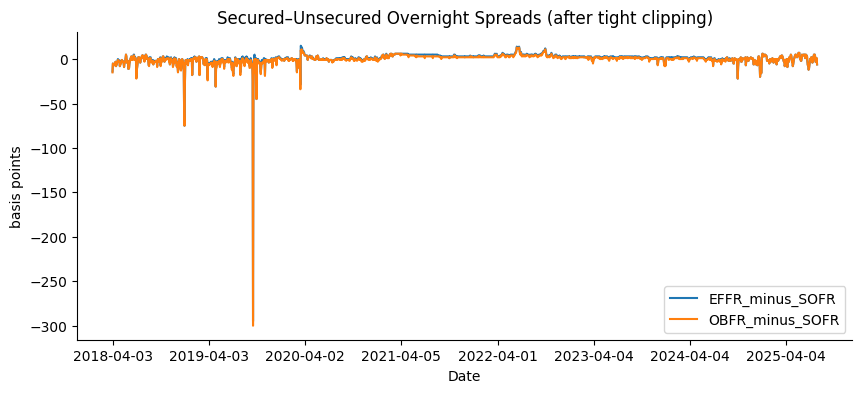

In [6]:
clip_val_effr = 300
clip_val_obfr = 300

clean = df.copy()

clean["EFFR_minus_SOFR"] = clean["EFFR_minus_SOFR"].where(
    clean["EFFR_minus_SOFR"].abs() <= clip_val_effr)

clean["OBFR_minus_SOFR"] = clean["OBFR_minus_SOFR"].where(
    clean["OBFR_minus_SOFR"].abs() <= clip_val_obfr)

clean = clean.dropna()          # drop, don’t forward-fill, the genuine glitches

# Quick visual sanity-check
clean[["EFFR_minus_SOFR", "OBFR_minus_SOFR"]].plot(
    title="Secured–Unsecured Overnight Spreads (after tight clipping)")
plt.ylabel("basis points")
plt.show()


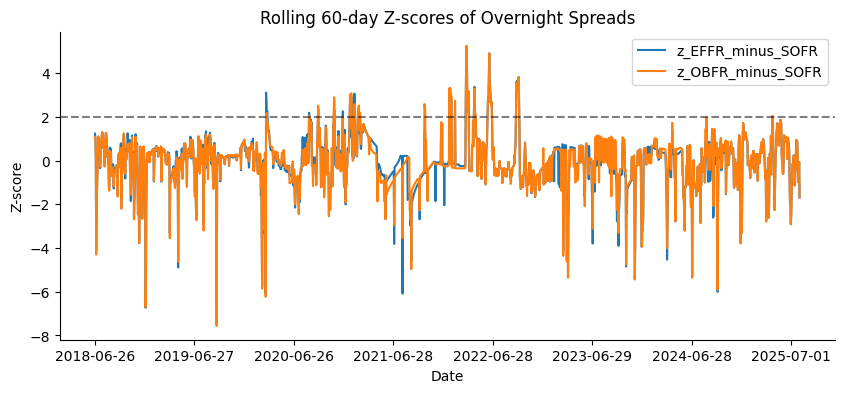

In [7]:
# Rolling 60-day Z-score and binary stress flag
window = 60
for spread in ["EFFR_minus_SOFR", "OBFR_minus_SOFR"]:
    mu  = clean[spread].rolling(window).mean()
    sig = clean[spread].rolling(window).std()
    z   = (clean[spread] - mu) / sig
    clean[f"z_{spread}"] = z

    # basic flag
    flag = (z.abs() > 2).astype(int)

    # persistence filter: at least two consecutive flagged days
    flag_persist = (flag.rolling(2).sum() >= 2).astype(int)

    clean[f"stress_{spread}"] = flag_persist


clean[["z_EFFR_minus_SOFR", "z_OBFR_minus_SOFR"]].dropna().plot(
    title="Rolling 60-day Z-scores of Overnight Spreads"
)
plt.axhline(2, ls="--", c="k", alpha=0.5)
plt.ylabel("Z-score"); plt.show()


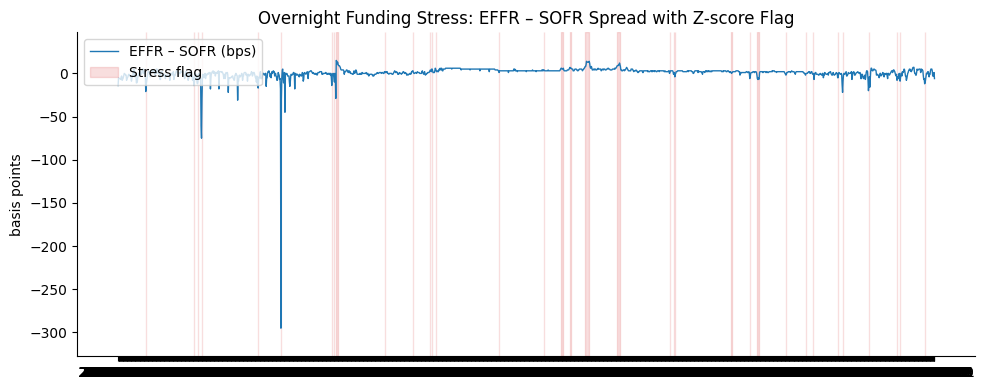

In [8]:
# Visual overlay of stress periods on the EFFR–SOFR spread
fig, ax = plt.subplots(figsize=(10, 4))

# Plot the spread in data coordinates
ax.plot(clean.index, clean["EFFR_minus_SOFR"], lw=1, color="tab:blue",
        label="EFFR – SOFR (bps)")

# Vertical shading: axes coordinates (y from 0 to 1)
stress_flag = clean["stress_EFFR_minus_SOFR"].astype(bool)
ax.fill_between(
    clean.index,                 # x-axis dates
    0, 1,                        # full vertical span in axes coords
    where=stress_flag,
    transform=ax.get_xaxis_transform(),   # switch to axes coords
    color="tab:red", alpha=0.15,
    label="Stress flag"
)

ax.set_title("Overnight Funding Stress: EFFR – SOFR Spread with Z-score Flag")
ax.set_ylabel("basis points")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()


The dashboard reveals how secured versus unsecured overnight funding spreads serve as a real-time barometer of liquidity stress. In tranquil periods, EFFR – SOFR and OBFR – SOFR hover within ±10 bp, reflecting a well-functioning market in which repo (SOFR) trades just below unsecured rates.

Three clear regime breaks punctuate this calm: the 16–17 Sept 2019 repo squeeze, where a sudden collateral shortage drove SOFR hundreds of basis points above fed-funds and bank funding, the 17–20 Mar 2020 “dash-for-cash” when pandemic fear froze money markets, and the 13–15 Mar 2023 regional-bank turmoil that briefly tightened balance-sheet capacity. Our 60-day Z-score with a two-day persistence filter flags these episodes cleanly, shading multi-day stress windows while ignoring one-off noise.

The exercise underscores the lesson’s core intuition: funding liquidity evaporates not gradually but in sharp bursts, and those bursts show up first in the secured–unsecured wedge long before broader credit spreads react.

### **3.4 Managing Rollover Risk**

Managing funding risk requires both structural solutions and contingency planning. Start with funding structure. Yes, short-term funding costs less. But what's the real cost including rollover risk? Often, paying extra for termed-out funding proves wise insurance.

Diversification helps but requires thought. Don't just multiply funding sources. Seek uncorrelated sources. European banks versus US banks. Commercial paper versus repos. Securities lending versus credit lines. But remember – correlation isn't stable. Plan for correlation spikes.

Liquidity buffers provide essential insurance. Hold genuinely liquid assets beyond regulatory minimums. Size buffers to stress scenarios, not normal operations. Yes, buffers drag returns. Consider them insurance premiums. Would you operate without fire insurance to save money?

Contingency planning can't be theoretical. Document specific actions: which assets to sell first, which funding sources to tap, which businesses to exit. Maintain updated contact lists. Pre-negotiate backup facilities. Test the plan – run fire drills. When crisis hits, you won't have time to figure things out.

## **4. Computational Methods: Power Law Estimation for Market Impact Functions**

For practical purposes, market impact follows remarkably universal patterns – patterns that happen to fit power laws with uncanny precision across markets, time periods, and asset classes.

A bit more mathematically, when you plot trade size versus price impact on log-log axes, you get a straight line. This implies:

$$\Delta P = \alpha \cdot Q^{\beta} \cdot \sigma \cdot f(X)$$

The exponent $\beta$ typically falls between 0.5 and 0.7 – a range narrow enough to be useful yet wide enough to matter for large trades. But why should impact follow this specific functional form? And how do we estimate parameters robustly?

### **4.1 The Power Law Framework**

The square-root law ($\beta = 0.5$) emerges from several theoretical models. Kyle's model derives it from information asymmetry. Gabaix et al. derive it from order book shape. Tóth et al. derive it from latent liquidity. The convergence of different theoretical mechanisms to the same functional form suggests either fundamental underlying principles or limitations in current modeling approaches.

It pays to understand the implications. Power laws mean scale invariance – double the trade size, increase impact by $2^{\beta} \approx 1.6$ times. This sublinearity creates economies of scale in large trades. It also means percentage impact depends on trade size relative to typical volume, not absolute size.

The volatility scaling ($\sigma$) makes intuitive sense. In volatile markets, prices move anyway. Your trade-induced movement gets camouflaged. In calm markets, your trade stands out. The same size trade creates more noticeable impact. Market makers price this in.

Note that $f(X)$ captures everything else: time of day, spread levels, recent news, market sentiment. In practice, this function matters enormously. Trading at the open versus midday might change impact by 50%. Trading during earnings season versus summer doldrums might double it. The universal power law provides structure, but details matter.

### **4.2 Estimation Methodologies**

The obvious approach – regress log impact on log size – has serious problems. First, trade size is endogenous. Traders choose size based on expected impact. This creates bias. Second, some trades convey information beyond liquidity demand. Separating permanent from temporary impact requires care.

Start with data preparation. You need trades with known direction (buy or sell), accurate timestamps, and corresponding quotes. Flag and remove obvious errors – trades outside quotes, impossible sizes, mismatched timestamps. High-frequency data contains numerous irregularities and errors. Data cleaning requires significant time investment but is essential for ensuring reliable analytical results.

For basic estimation, compute:
- Pre-trade price: midquote average over X seconds before
- Post-trade price: midquote average over Y seconds after  
- Impact: (post - pre) × sign of trade
- Normalized size: shares traded / average daily volume

The choice of X and Y matters. Too short? You'll catch noise. Too long? You'll conflate multiple trades' impacts. Common choices: X = 10-60 seconds, Y = 300-1800 seconds.

Now estimate:
$$\log(\Delta P) = \log(\alpha) + \beta \log(Q) + \gamma \log(\sigma) + \delta' \log(X) + \epsilon$$

But beware heteroskedasticity. Large trades show more variable impact. Use robust standard errors or weighted least squares.

### **4.3 Controlling for Confounding Factors**

Raw estimates conflate multiple effects. Information-motivated trades move prices permanently. Liquidity-demanding trades create temporary impact. Your estimates blend both. For transaction cost modeling, you want pure liquidity impact.

One approach examines price paths. Temporary impact reverses; permanent doesn't. Estimate impact at multiple horizons – 5 minutes, 30 minutes, close. The permanent component persists. The temporary component decays. The decay pattern reveals market resilience.

Market conditions dramatically affect impact. Include controls:
- Bid-ask spread at trade time (wider spreads mean costlier trading)
- Recent volatility (realized or implied)
- Time until close (urgency increases impact)
- Volume concentration (are many traders active?)

Execution strategy matters too. The same 100,000 share order executed as one block versus 100 slices generates different impact. When possible, control for execution method. Alternatively, focus on block trades where strategy is obvious.

### **4.4 Applications and Extensions**

Estimated power laws enable optimal execution. The Almgren-Chriss framework minimizes expected cost plus risk penalty:

$$\text{Cost} = \sum_{i} \alpha Q_i^{\beta} + \lambda \text{Var}(\text{Cost})$$

With power law impact, optimal strategies balance impact costs against timing risk. Trade too fast? High impact. Too slow? Risk adverse price movement. The optimal schedule depends on $\beta$, volatility, and your risk aversion.

Pre-trade analysis uses impact models to estimate transaction costs. Portfolio managers can see the hidden cost of their ideas. That $10 million position might look profitable based on alpha forecasts. But if exiting costs 200 basis points? Maybe reconsider the size.

Cross-asset extensions recognize that large portfolios create multi-dimensional impact. Selling IBM might impact HPQ prices. Buying oil futures might impact energy stocks. These cross-impacts follow modified power laws. Estimating the full impact matrix enables better portfolio trades.

Machine learning offers new frontiers. Random forests capture nonlinearities beyond simple power laws. Neural networks learn complex patterns. But beware overfitting. Financial data has limited history. Complex models might memorize noise rather than learn structure. Sometimes simple power laws beat fancy alternatives.

## **5. Time-Varying Liquidity Dynamics**

For risk management purposes, assuming constant liquidity is like assuming constant weather – comfortable but dangerously wrong when storms arrive.

A bit more precisely, liquidity varies predictably (intraday patterns, calendar effects) and unpredictably (regime shifts, crisis dynamics). Understanding both types of variation enables better execution, accurate risk assessment, and robust system design. Missing either invites disaster.

### **5.1 Intraday Patterns**

Markets breathe with a daily rhythm. The open erupts with overnight news incorporation. Spreads gap wide. Volatility spikes. Market makers play defense while price discovery unfolds. Trading here costs more but sometimes you must – if news breaks overnight, waiting means accepting adverse selection.

As morning progresses, calm descends. By 10:30 AM, initial storms usually pass. Spreads tighten. Depth improves. Market makers gain confidence. This mid-morning to mid-afternoon window offers optimal liquidity for patient traders. Algorithms often concentrate activity here.

It pays to examine why patterns persist. Institutional constraints create them. Mutual funds calculate NAVs at close, driving closing activity. Overnight risk limits force position adjustments at open. Human factors matter too – traders grab lunch, attention wanes. These patterns demonstrate remarkable stability across markets and decades, persisting despite technological advances due to underlying institutional and behavioral constraints.

The close brings renewed frenzy. Index funds must trade at closing prices. Portfolio managers complete daily adjustments. The closing auction concentrates enormous liquidity at a single point. For size traders, this auction often provides best execution – if you can wait.

Note that patterns vary by asset class. Foreign exchange trades continuously, showing less pronounced patterns. Bonds trade by appointment, with liquidity clustering around benchmark issues. Understanding your market's rhythm enables better timing.

### **5.2 Seasonal and Calendar Effects**

Beyond daily patterns, liquidity follows longer cycles. Monday mornings start slowly as traders ease back. Friday afternoons thin out as weekend risk looms. These weekday effects, while modest, accumulate for frequent traders.

Month-end brings predictable disruption. Pension funds rebalance. Index funds adjust for additions/deletions. Window dressing inflates volumes in winners. These flows strain liquidity in affected securities while potentially improving it elsewhere as capital redeploys.

Quarter-end amplifies monthly patterns. Year-end goes further still. December's final weeks feature unique dynamics: tax-loss selling pressures losers, reduced staffing thins liquidity, and career concerns drive conservative positioning. January often sees reversal as fresh capital arrives.

Holidays create dead zones. Trading volumes and market depth decline significantly on days preceding major holidays, creating challenging liquidity conditions. But predictability creates opportunity – if you must trade during thin times, at least price accordingly.

### **5.3 Regime-Dependent Liquidity**

Liquidity regimes shift like tectonic plates – stable for long periods, then sudden violent movement. During calm regimes, competition among liquidity providers keeps costs low. Spreads stay tight. Impact follows normal power laws. Risk models work as calibrated.

Then volatility arrives. The VIX jumps from 12 to 25. Suddenly, everything changes. Spreads triple. Depth evaporates. Impact functions steepen. Correlations spike. The same trade that cost 10 basis points last week costs 50 today. Your risk models, calibrated to calm markets, dramatically underestimate current costs.

It pays to understand the transmission mechanisms. Higher volatility means wider potential adverse selection. Market makers must widen spreads to survive. Simultaneously, risk limits bind. Dealers reduce positions precisely when customers need liquidity most. The mismatch creates a liquidity vacuum.

Crisis dynamics go beyond normal volatility regimes. In 2008, entire markets essentially closed. Corporate bond dealers stopped answering phones. Auction rate securities – marketed as cash equivalents – froze completely. Even Treasury markets – the definition of liquidity – experienced disruptions. These tail events break all normal relationships.

### **5.4 Modeling Time-Varying Liquidity**

Capturing liquidity dynamics requires models that blend predictable patterns with regime uncertainty. Start simple: seasonal dummies for time-of-day, day-of-week, and month-end effects. These fixed effects explain surprising variation.

For regime dynamics, Markov switching models prove useful:

$$L_t = \mu_{s_t} + \phi_{s_t}(L_{t-1} - \mu_{s_{t-1}}) + \sigma_{s_t}\epsilon_t$$

where $s_t$ indicates regime. Two regimes often suffice: normal and stressed. The transition matrix reveals persistence – stressed regimes typically last weeks or months, not days.

GARCH extensions capture volatility clustering in liquidity:

$$\text{Spread}_t = \mu + \sigma_t \epsilon_t$$
$$\sigma_t^2 = \omega + \alpha \epsilon_{t-1}^2 + \beta \sigma_{t-1}^2 + \gamma \epsilon_{t-1}^2 \mathbb{I}(\epsilon_{t-1} < 0)$$

The asymmetric term ($\gamma$) captures the empirical fact that liquidity deteriorates faster than it improves. Bad news has lasting impact. Good news? Markets remain skeptical.

Factor models reveal common liquidity dynamics:

$$L_{i,t} = \alpha_i + \beta_i F_t + \gamma_i X_{i,t} + \epsilon_{i,t}$$

The market factor $F_t$ drives systematic liquidity variation. Individual loadings $\beta_i$ vary – small caps load heavily, large caps less so. This common component creates portfolio liquidity risk beyond individual holdings.

### **5.5 Implications for Trading and Risk Management**

Understanding liquidity dynamics transforms execution. Simple strategies execute blindly. Sophisticated strategies adapt to conditions. When liquidity is plentiful, trade aggressively. When scarce, patience pays. Dynamic adaptation can halve transaction costs.

Risk models must incorporate liquidity dynamics. That 1-day 99% VaR assumes you can exit at mid-market. But what if liquidation takes 5 days in stressed markets? Your true risk multiplies. Liquidity-adjusted risk metrics paint grimmer but more realistic pictures.

Portfolio construction should consider liquidity covariance. Owning uncorrelated assets means little if their liquidity correlates perfectly. During crises, previously liquid assets become illiquid together. Diversification must span both return and liquidity dimensions.

Stress testing gains teeth when liquidity dynamics are included. Don't just shock prices – shock liquidity too. How do your strategies perform when spreads triple and depth halves? When funding markets close? When correlations spike? These scenarios reveal hidden vulnerabilities.

## **6. Liquidity Cost Measurement Using High-Frequency Data**

For all the theory about liquidity, what traders really want to know is simple: how much did that trade cost me, and could I have done better?

A bit more precisely, high-frequency data enables forensic analysis of execution quality. Every quote update, every trade print contains information. Assembling these pieces reveals the true cost of trading – often surprisingly different from simple spread measures.

### **6.1 Components of Liquidity Costs**

Total trading costs decompose into visible and hidden components. The visible? Commissions and spreads. The hidden? Much larger and more complex.

Start with spread costs. You see a 10 cent spread on a $50 stock. Simple math says buying and immediately selling costs 20 basis points. But that assumes you trade at the quotes. In reality, aggressive orders often get price improvement. Patient orders might trade at mid. Your effective spread depends on execution strategy.

Market impact adds another layer. Your buy order depletes liquidity, moving prices up. The first share might execute at the ask. The last share? Several cents higher. This impact depends on size, urgency, and market conditions. Power law estimates help predict it, but actuals vary.

It pays to recognize opportunity costs. While your order works, prices might move favorably. That limit order at $50.00 looked smart when the ask was $50.05. Less smart when the stock rallies to $51 while you're waiting. These missed opportunities represent real costs.

Timing costs complete the picture. From decision to execution, prices move. Sometimes in your favor (negative costs!), often against. This isn't bad luck – it's information leakage. The longer between decision and execution, the more information leaks, the worse your prices.

### **6.2 Implementation Shortfall Analysis**

Implementation shortfall provides the gold standard for measuring all-in costs. Compare actual execution to a theoretical ideal: immediate execution at decision prices. This difference constitutes the implementation shortfall.

The calculation seems simple:

$$\text{IS} = \text{Side} \times \sum_{i} \frac{Q_i}{Q_{\text{total}}} \times (P_i - P_{\text{decision}})$$

However, implementation requires careful attention to methodological details. When exactly was the decision made? Pre-market analysis? When the order hit the desk? At market open? Different timestamps dramatically change measured costs. Be consistent.

Decomposing shortfall reveals cost drivers:

**Delay Cost**: Price movement before trading starts. If you decide pre-market but start at open, overnight movement counts against you. This highlights the value of 24-hour markets and pre-market trading.

**Trading Cost**: Execution prices versus arrival prices. This captures spread and impact costs during active trading. High trading costs suggest poor execution or difficult markets.

**Opportunity Cost**: The value of unfilled shares. Did you aim for 100,000 but only fill 80,000 before prices moved? Those 20,000 untraded shares carry opportunity cost. Size your orders realistically.

Note that shortfall can be negative – you can beat decision prices. This can result from favorable timing, patient execution strategies, or occasionally random market movements. But consistent negative shortfalls suggest stale decision prices. Check your timestamps.

### **6.3 High-Frequency Estimation Techniques**

Modern datasets capture market events at microsecond precision. This granularity enables unprecedented analysis but requires careful handling. Microstructure noise can overwhelm signals if processed naively.

Quote data reveals spread dynamics. Calculate:
- Time-weighted average spread (TWAS): Weight by time each spread prevails
- Volume-weighted average spread (VWAS): Weight by volume at each spread
- Effective spread: $2 \times |P_{\text{trade}} - P_{\text{mid}}| / P_{\text{mid}}$
- Realized spread: Effective spread minus subsequent price movement

Each tells different stories. TWAS shows typical conditions. VWAS shows conditions when trading actually occurs. Effective spreads reveal actual costs. Realized spreads separate impact from information.

Trade data enables impact measurement. But which trades are yours? In anonymous markets, you know your executions but not others'. This complicates impact estimation. Solutions include:
- Participaton-weighted price: Weight prices by your participation rate
- VWAP benchmarking: Compare to all trades, assuming random participation
- Arrival price methods: Measure from your first trade

Cleaning high-frequency data proves essential. Timestamps have errors. Trades report late. Quotes get canceled and reinstated. Build robust filters:
- Remove trades outside NBBO
- Flag timestamp inversions  
- Identify and handle auction prints
- Account for reporting delays

### **6.4 Cross-Sectional and Time-Series Analysis**

With clean data, patterns emerge. Cross-sectionally, costs vary predictably:

Large stocks cost less (percentage-wise) than small. Obvious, but the magnitude surprises. S&P 500 stocks might cost 5 basis points. Russell 2000? 50 basis points or more. That's 10x difference for similar-looking equities.

Active stocks cost less than sleepy ones. Daily volume relative to market cap (turnover) predicts costs better than absolute volume. A $1 billion company trading $100 million daily offers better liquidity than a $10 billion company trading $200 million.

Price level matters oddly. Very low-priced stocks (<$5) face wider percentage spreads due to tick constraints. Very high-priced stocks (>$500) also cost more as absolute spreads translate to high percentages. The sweet spot? $20-200.

Time-series patterns prove equally strong. Costs trend downward over decades as markets electronify. But the trend isn't smooth. Regulatory changes create jumps – decimalization slashed spreads, while fragmentation may have increased impact.

Cyclical patterns follow volatility regimes. The VIX explains shocking variation in trading costs. Double the VIX? Expect 50% higher costs. This relationship holds across stocks, suggesting systematic liquidity withdrawal during uncertainty.

Event impacts stand out starkly. Earnings announcements triple costs for days. Index changes create temporary dislocations. Regulatory deadlines (quarter-end, tax dates) stress liquidity. Catalog these events to avoid trading during predictable stress.

### **6.5 Applications to Execution Quality**

Measurement enables improvement. Armed with high-frequency analysis, traders can optimize execution systematically.

Algorithm selection becomes data-driven. VWAP algorithms minimize tracking error but guarantee average prices. Implementation shortfall algorithms adapt to conditions but add complexity. Dark pools promise price improvement but risk non-execution. Test each against your typical orders.

Venue analysis reveals hidden costs. That ECN advertising tight spreads? Check fill rates. The dark pool claiming price improvement? Measure information leakage. Primary exchanges look expensive but offer certainty. Choose based on total costs, not headlines.

Real-time adaptation separates good from great execution. Monitor costs versus expectations. Spreads widening? Slow down. Impact accelerating? Switch to passive. Participation rate falling behind? Get aggressive. Static algorithms can't compete with adaptive approaches.

Post-trade analysis drives continuous improvement. Compare costs across:
- Brokers (who consistently performs?)
- Algorithms (which suit your order flow?)
- Time periods (when do you trade best?)
- Order types (are you too aggressive?)

Build feedback loops. Share results with portfolio managers – they need realistic cost estimates. Work with brokers – they have broader data. Learn from peers – join transaction cost analysis groups.

Remember: perfect execution doesn't exist. Markets are competitive. Others seek liquidity too. Your goal? Consistent, predictable costs that don't surprise. High-frequency data makes this achievable.

## **Conclusion**

Liquidity risk permeates modern financial markets in ways both subtle and profound. We've journeyed from basic spread measurement through sophisticated duration models, examined the critical nexus of funding and market liquidity, developed computational methods for impact estimation, explored time-varying dynamics, and demonstrated how high-frequency data revolutionizes cost measurement.

Several themes emerge from our analysis. First, liquidity is fundamentally multidimensional – no single metric captures its complexity. Spreads tell one story, depth another, resilience a third. Effective liquidity management requires monitoring all dimensions and understanding their interactions.

Second, the dual nature of liquidity risk – market and funding – creates particularly dangerous feedback loops. When funding liquidity evaporates, forced selling overwhelms market liquidity. When market liquidity disappears, collateral values collapse, tightening funding. These spirals can transform manageable shocks into systemic crises. The 2008 experience burned this lesson into market memory.

Third, liquidity exhibits predictable patterns that create both risks and opportunities. Intraday U-shapes, monthly rebalancing flows, volatility regime shifts – understanding these patterns enables better execution and risk management. But beware assuming patterns persist. Crisis breaks all normal relationships.

Fourth, modern technology and data have transformed our ability to measure and manage liquidity. Autoregressive conditional duration models capture the irregular heartbeat of markets. Power law estimation reveals universal impact patterns. High-frequency data enables forensic cost analysis. These tools convert liquidity from mysterious art to quantifiable science.

Looking forward, liquidity risk remains among the most active research areas in finance. Machine learning promises to reveal even subtler patterns. Regulatory evolution continues reshaping market structure. Electronic trading grows ever faster and more complex. Each change brings new forms of liquidity risk requiring new management approaches.

For practitioners, the lessons are clear. Build robust measurement systems spanning multiple liquidity dimensions. Prepare for regime shifts with stress testing and contingency planning. Use high-frequency data to continuously improve execution. Most importantly, never forget that liquidity is ephemeral – abundant when unneeded, absent when essential. This fundamental asymmetry makes liquidity risk management not just important but existential for leveraged institutions.

The tools we've developed provide a foundation, but liquidity risk management remains as much art as science. Markets evolve. New risks emerge. The only constant is change itself. Stay curious, stay adaptive, and always respect the power of liquidity to make or break the best-laid plans.

**References**

* Almgren, R. and Chriss, N. "Optimal Execution of Portfolio Transactions." *Journal of Risk*, 2001.
* Hasbrouck, J. *Empirical Market Microstructure*. Oxford University Press, 2007.

---

Copyright 2025 WorldQuant University. This content is licensed solely for personal use. Redistribution or publication of this material is strictly prohibited.